# Air Pollution and Weather Patterns
**Goal:** explore how observed pollution measurements vary across locations and weather conditions.

## Important data limitation
The accompanying README describes **current** weather and air-pollution measurements for the three biggest cities per country, generated at one collection time. This is a cross-sectional snapshot, not a historical time series. Therefore, this dataset alone cannot reliably establish seasonal patterns or trends over time. The `season` column may be derived from the collection date; verify it before interpreting it. For true seasonal analysis, collect repeated measurements over months or use a historical dataset.

### Project flow
1. Load and understand the data.
2. Clean types, missing values, duplicates, units, and implausible values.
3. Create a small set of analysis-ready features.
4. Explore pollution distributions, location differences, and weather relationships.
5. Run five simple hypothesis tests at α = 0.05.
6. Write conclusions with caveats and prepare outputs for Power BI.

**Main outcomes:** `aqi`, `pm2_5`, and `pm10`. Weather fields include temperature, humidity, wind speed, pressure, rain, and clouds.

### SOURCE LINK
https://www.kaggle.com/datasets/xjoannax88/global-weather-and-air-pollution-dataset/code
### Deliverables checklist
- Reproducible notebook with code and interpretations
- Original raw CSV and separately exported cleaned CSV
- Source register and dataset limitations
- At least six labelled visualisations
- Concise report or presentation with evidence-backed conclusions


## 1. Install and import libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 100)


## Project understanding and scope

### Problem statement
Air pollution can vary across places and weather conditions. This project explores whether observed pollutant measurements are associated with weather and location in the supplied OpenWeather snapshot.

### Objectives
- Describe the dataset, its units, coverage, missing values and quality issues.
- Clean and prepare one dataset for analysis.
- Explore pollution levels by location and weather conditions.
- Use descriptive statistics and five exploratory hypothesis tests at α = 0.05.
- Communicate findings with labelled charts and clear limitations.

### Scope and research questions
This notebook uses **one dataset only**, as requested. It is a cross-sectional snapshot, so it cannot support reliable seasonal or long-term trend claims. Research questions: (1) What are the dataset dimensions and measurement units? (2) Which columns have missing values? (3) What are the distributions of PM2.5 and PM10? (4) How do PM2.5 values differ across cities? (5) How are PM2.5 and wind speed associated? (6) How do pollutant measures correlate? (7) Does observed PM2.5 vary across weather categories? (8) Are high-AQI proportions different between rainy and non-rainy observations?

### Source register
| Source | Role | Notes |
|---|---|---|
| `openweather_weather_airpollution_top3cities_per_country.csv` | Primary dataset | Provided project CSV; record the download/collection date and original URL in your final submission if known. |
| OpenWeather API documentation (https://openweathermap.org/api) | Metadata/context reference | Use to verify field definitions; this is not a second dataset. |
| WHO air quality guidelines (https://www.who.int/publications/i/item/9789240034228) | Background reference | Context for interpreting air-quality concerns; do not treat AQI categories as WHO guideline thresholds. |

Do not invent a source URL or collection date if it was not supplied. Keep the original CSV unchanged and export a separate cleaned CSV.


## 2. Load the dataset
Place the provided CSV in the same folder as this notebook, or update `DATA_FILE` to its location.


In [2]:
#stroing the file name in variable 
DATA_FILE = "openweather_weather_airpollution_top3cities_per_country.csv"

# Load CSV file 
df = pd.read_csv(DATA_FILE)

# Show the dataset size and a preview.
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (108467, 88)


,collection_time_utc,source_weather,source_air,source_city_selection,units_weather,country_code,country_name,country_capital,country_population,continent,city_name,city_name_ascii,city_population,population_rank_in_country,city_timezone_geonames,geonames_feature_code,city_dem,geonameid,geonames_modification_date,geo_lat,geo_lon,weather_id,weather_main,weather_description,weather_icon,temp,feels_like,temp_min,temp_max,pressure,humidity,sea_level,grnd_level,visibility,wind_speed,wind_deg,wind_gust,clouds_all,rain_1h,rain_3h,snow_1h,snow_3h,timezone_shift_seconds,weather_time_unix,weather_time_utc,sunrise_unix,sunrise_utc,sunset_unix,sunset_utc,station_country,station_type,city_id_openweather,city_name_api,cod,wind_compass,is_daytime,temp_category,comfort_proxy,has_rain,has_snow,air_time_unix,air_time_utc,aqi,pm2_5,pm10,co,no,no2,o3,so2,nh3,aqi_label,pm25_category,weather_datetime_utc,air_datetime_utc,year,month,day,hour,day_of_week,is_weekend,season,temp_humidity_interaction,wind_pm25_interaction,pressure_temp_interaction,target_aqi_class,target_pm25,target_pm10
0,2026-04-24T07:06:06Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AD,Andorra,Andorra la Vella,77006,EU,Andorra la Vella,Andorra la Vella,20430,1,Europe/Andorra,PPLC,1037,3041563,03-03-2020,42.50779,1.52109,803,Clouds,broken clouds,04d,14.11,13.53,13.14,14.11,1020,75,1020,816,4676.0,0.45,242,1.34,69,0.0,0.0,0.0,0,7200,1777014366,2026-04-24T07:06:06Z,1777006737,2026-04-24T04:58:57Z,1777056292,2026-04-24T18:44:52Z,AD,stations,3041563,Andorra la Vella,200,WSW,1,mild,21.61,0,0,1777014366,2026-04-24T07:06:06Z,2,4.71,10.81,135.40,0.17,6.88,66.71,0.33,16.07,fair,low,2026-04-24T07:06:06Z,2026-04-24T07:06:06Z,2026,4,24,7,4,0,spring,1058.25,2.1195,14392.20,2,4.71,10.81
1,2026-04-24T07:06:06Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AD,Andorra,Andorra la Vella,77006,EU,les Escaldes,les Escaldes,15853,2,Europe/Andorra,PPLA,1033,3040051,13-04-2026,42.50729,1.53414,803,Clouds,broken clouds,04d,14.33,13.78,13.36,14.33,1020,75,1020,816,4676.0,0.45,242,1.34,69,0.0,0.0,0.0,0,7200,1777014366,2026-04-24T07:06:06Z,1777006734,2026-04-24T04:58:54Z,1777056289,2026-04-24T18:44:49Z,AD,stations,3040051,Escaldes-Engordany,200,WSW,1,mild,21.83,0,0,1777014366,2026-04-24T07:06:06Z,2,4.71,10.81,135.40,0.17,6.88,66.71,0.33,16.07,fair,low,2026-04-24T07:06:06Z,2026-04-24T07:06:06Z,2026,4,24,7,4,0,spring,1074.75,2.1195,14616.60,2,4.71,10.81
2,2026-04-24T07:06:07Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AE,United Arab Emirates,Abu Dhabi,9630959,AS,Dubai,Dubai,3790000,1,Asia/Dubai,PPLA,24,292223,13-04-2026,25.07725,55.30927,800,Clear,clear sky,01d,35.84,34.65,35.84,36.05,1009,24,1009,1006,10000.0,3.09,15,3.27,8,0.0,0.0,0.0,0,14400,1777014101,2026-04-24T07:01:41Z,1776995317,2026-04-24T01:48:37Z,1777041897,2026-04-24T14:44:57Z,AE,stations,292224,Dubai,200,NNE,1,hot,38.24,0,0,1777014367,2026-04-24T07:06:07Z,4,28.41,116.85,187.29,5.33,14.91,90.17,7.62,0.40,poor,high,2026-04-24T07:01:41Z,2026-04-24T07:06:07Z,2026,4,24,7,4,0,spring,860.16,87.7869,36162.56,4,28.41,116.85
3,2026-04-24T07:06:07Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AE,United Arab Emirates,Abu Dhabi,9630959,AS,Abu Dhabi,Abu Dhabi,1807000,2,Asia/Dubai,PPLC,6,292968,27-03-2024,24.45118,54.39696,800,Clear,clear sky,01d,33.02,33.40,33.02,36.07,1010,38,1010,1010,10000.0,3.60,20,NaN,0,0.0,0.0,0.0,0,14400,1777014367,2026-04-24T07:06:07Z,1776995578,2026-04-24T01:52:58Z,1777042074,2026-04-24T14:47:54Z,AE,stations,8056564,Al Amān,200,NNE,1,hot,36.82,0,0,1777014367,2026-04-24T07:06:07Z,3,18.07,97.68,113.88,0.13,0.73,109.45,1.00,0.06,moderate,moderate,2026-04-24T07:06:07Z,2026-04-24T07:06:07Z,2026,4,24,7,4,0,spring,1254.76,65.0520,33350.20,3,18.07,97.68
4,2026-04-24T07:06:07Z,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AE,United Arab Emirates,Abu Dhabi,9630959,AS,Sharjah,Sharjah,1800000,3,Asia/Dubai,PPLA,15,292672,13-04-2026,25.33420,55.4122

## 3. Understanding the data
Check column types, numeric summaries, and missingness before making changes.

In [3]:
# Review column names and data types.
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 108467 entries, 0 to 108466
Data columns (total 88 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   collection_time_utc         107884 non-null  str    
 1   source_weather              108467 non-null  str    
 2   source_air                  108467 non-null  str    
 3   source_city_selection       108467 non-null  str    
 4   units_weather               108467 non-null  str    
 5   country_code                108467 non-null  str    
 6   country_name                108467 non-null  str    
 7   country_capital             108467 non-null  str    
 8   country_population          108467 non-null  int64  
 9   continent                   94719 non-null   str    
 10  city_name                   108467 non-null  str    
 11  city_name_ascii             108467 non-null  str    
 12  city_population             108467 non-null  int64  
 13  population_rank_in_countr

In [6]:
# Summarise numeric columns (count, mean, spread, minimum, maximum).
df.describe(include="number").T

,count,mean,std,min,25%,50%,75%,max
country_population,108467.0,3.929852e+07,1.448046e+08,3.371800e+04,2.108132e+06,8.606316e+06,2.849869e+07,1.463866e+09
city_population,108467.0,1.435679e+06,2.787402e+06,1.529800e+04,1.140840e+05,4.204450e+05,1.482200e+06,3.205416e+07
population_rank_in_country,108467.0,1.955424e+00,8.181255e-01,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,3.000000e+00
city_dem,108467.0,2.549656e+02,1.006986e+03,-9.999000e+03,1.600000e+01,5.800000e+01,3.900000e+02,3.782000e+03
geonameid,108467.0,2.264771e+06,1.905175e+06,5.365400e+04,9.217530e+05,2.236500e+06,3.193044e+06,1.352732e+07
geo_lat,108467.0,1.907410e+01,2.385739e+01,-4.353333e+01,4.938100e+00,1.797102e+01,4.037767e+01,6.413548e+01
geo_lon,108467.0,1.988743e+01,6.427852e+01,-1.752011e+02,-9.471220e+00,2.101178e+01,4.808389e+01,1.785131e+02
weather_id,108467.0,7.618097e+02,1.034969e+02,2.000000e+02,8.000000e+02,8.010000e+02,8.030000e+02,8.040000e+02
temp,108467.0,2.246004e+01,6.793277e+00,-1.493000e+01,1.781000e+01,2.366000e+01,2.735000e+01,4.211000e+01
feels_like,108467.0,2.334487e+01,8.340209e+00,-1.933000e+01,1.753000e+01,2.398000e+01,2.954000e+01,4.684000e+01


In [4]:
# Count missing values and show the most affected columns.
missing = df.isna().sum().sort_values(ascending=False)
#showing how many values are missing in each columns , shwoing in decending order 
missing[missing > 0].to_frame("missing_count")

,missing_count
wind_gust,33120
continent,13748
sunset_utc,583
collection_time_utc,583
sunrise_utc,583
weather_time_utc,583
air_time_utc,583
station_country,186
city_name_api,186
visibility,102


## 4. Cleaning
Keep the original DataFrame untouched and create a working copy. Do not replace missing pollution readings with zero: zero means a measured value of zero, while missing means no reading.

In [5]:
# Work on a copy so the original data remains available for comparison.
data = df.copy()

# Parse timestamps as UTC; invalid timestamps become missing (NaT).
for col in ["collection_time_utc", "weather_time_utc", "air_time_utc",
            "weather_datetime_utc", "air_datetime_utc"]:
    if col in data.columns:
        data[col] = pd.to_datetime(data[col], errors="coerce", utc=True)


In [6]:
# Convert key measurements to numeric; invalid text becomes NaN.
numeric_cols = [
    "aqi", "pm2_5", "pm10", "no2", "o3", "so2", "co", "nh3",
    "temp", "feels_like", "humidity", "pressure", "wind_speed",
    "wind_deg", "clouds_all", "visibility", "rain_1h", "rain_3h"
]
for col in numeric_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")
        

In [7]:
data.head()

,collection_time_utc,source_weather,source_air,source_city_selection,units_weather,country_code,country_name,country_capital,country_population,continent,city_name,city_name_ascii,city_population,population_rank_in_country,city_timezone_geonames,geonames_feature_code,city_dem,geonameid,geonames_modification_date,geo_lat,geo_lon,weather_id,weather_main,weather_description,weather_icon,temp,feels_like,temp_min,temp_max,pressure,humidity,sea_level,grnd_level,visibility,wind_speed,wind_deg,wind_gust,clouds_all,rain_1h,rain_3h,snow_1h,snow_3h,timezone_shift_seconds,weather_time_unix,weather_time_utc,sunrise_unix,sunrise_utc,sunset_unix,sunset_utc,station_country,station_type,city_id_openweather,city_name_api,cod,wind_compass,is_daytime,temp_category,comfort_proxy,has_rain,has_snow,air_time_unix,air_time_utc,aqi,pm2_5,pm10,co,no,no2,o3,so2,nh3,aqi_label,pm25_category,weather_datetime_utc,air_datetime_utc,year,month,day,hour,day_of_week,is_weekend,season,temp_humidity_interaction,wind_pm25_interaction,pressure_temp_interaction,target_aqi_class,target_pm25,target_pm10
0,2026-04-24 07:06:06+00:00,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AD,Andorra,Andorra la Vella,77006,EU,Andorra la Vella,Andorra la Vella,20430,1,Europe/Andorra,PPLC,1037,3041563,03-03-2020,42.50779,1.52109,803,Clouds,broken clouds,04d,14.11,13.53,13.14,14.11,1020,75,1020,816,4676.0,0.45,242,1.34,69,0.0,0.0,0.0,0,7200,1777014366,2026-04-24 07:06:06+00:00,1777006737,2026-04-24T04:58:57Z,1777056292,2026-04-24T18:44:52Z,AD,stations,3041563,Andorra la Vella,200,WSW,1,mild,21.61,0,0,1777014366,2026-04-24 07:06:06+00:00,2,4.71,10.81,135.40,0.17,6.88,66.71,0.33,16.07,fair,low,2026-04-24 07:06:06+00:00,2026-04-24 07:06:06+00:00,2026,4,24,7,4,0,spring,1058.25,2.1195,14392.20,2,4.71,10.81
1,2026-04-24 07:06:06+00:00,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AD,Andorra,Andorra la Vella,77006,EU,les Escaldes,les Escaldes,15853,2,Europe/Andorra,PPLA,1033,3040051,13-04-2026,42.50729,1.53414,803,Clouds,broken clouds,04d,14.33,13.78,13.36,14.33,1020,75,1020,816,4676.0,0.45,242,1.34,69,0.0,0.0,0.0,0,7200,1777014366,2026-04-24 07:06:06+00:00,1777006734,2026-04-24T04:58:54Z,1777056289,2026-04-24T18:44:49Z,AD,stations,3040051,Escaldes-Engordany,200,WSW,1,mild,21.83,0,0,1777014366,2026-04-24 07:06:06+00:00,2,4.71,10.81,135.40,0.17,6.88,66.71,0.33,16.07,fair,low,2026-04-24 07:06:06+00:00,2026-04-24 07:06:06+00:00,2026,4,24,7,4,0,spring,1074.75,2.1195,14616.60,2,4.71,10.81
2,2026-04-24 07:06:07+00:00,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AE,United Arab Emirates,Abu Dhabi,9630959,AS,Dubai,Dubai,3790000,1,Asia/Dubai,PPLA,24,292223,13-04-2026,25.07725,55.30927,800,Clear,clear sky,01d,35.84,34.65,35.84,36.05,1009,24,1009,1006,10000.0,3.09,15,3.27,8,0.0,0.0,0.0,0,14400,1777014101,2026-04-24 07:01:41+00:00,1776995317,2026-04-24T01:48:37Z,1777041897,2026-04-24T14:44:57Z,AE,stations,292224,Dubai,200,NNE,1,hot,38.24,0,0,1777014367,2026-04-24 07:06:07+00:00,4,28.41,116.85,187.29,5.33,14.91,90.17,7.62,0.40,poor,high,2026-04-24 07:01:41+00:00,2026-04-24 07:06:07+00:00,2026,4,24,7,4,0,spring,860.16,87.7869,36162.56,4,28.41,116.85
3,2026-04-24 07:06:07+00:00,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AE,United Arab Emirates,Abu Dhabi,9630959,AS,Abu Dhabi,Abu Dhabi,1807000,2,Asia/Dubai,PPLC,6,292968,27-03-2024,24.45118,54.39696,800,Clear,clear sky,01d,33.02,33.40,33.02,36.07,1010,38,1010,1010,10000.0,3.60,20,NaN,0,0.0,0.0,0.0,0,14400,1777014367,2026-04-24 07:06:07+00:00,1776995578,2026-04-24T01:52:58Z,1777042074,2026-04-24T14:47:54Z,AE,stations,8056564,Al Amān,200,NNE,1,hot,36.82,0,0,1777014367,2026-04-24 07:06:07+00:00,3,18.07,97.68,113.88,0.13,0.73,109.45,1.00,0.06,moderate,moderate,2026-04-24 07:06:07+00:00,2026-04-24 07:06:07+00:00,2026,4,24,7,4,0,spring,1254.76,65.0520,33350.20,3,18.07,97.68
4,2026-04-24 07:06:07+00:00,OpenWeather,OpenWeather,GeoNames cities15000 + countryInfo,metric,AE,United Arab Emir

In [8]:
entry_duplicate= df.duplicated(keep="first").sum()
print(F"Total Exact Duplicate rows :{entry_duplicate}")

#if i want to same same country name count or any colum just replace with column name 
# entry_duplicate= df.columnname.duplicated(keep="first").sum()
# print(F"Total Exact Duplicate rows :{entry_duplicate}")

Total Exact Duplicate rows :0


In [9]:
# Remove exact duplicate rows.
before = len(data)
data = data.drop_duplicates()
print("Exact duplicate rows removed:", before - len(data))


Exact duplicate rows removed: 0


In [10]:
# Inspect timestamp/location duplicates. Keep them for now; investigate before dropping.
key_cols = [c for c in ["city_id_openweather", "air_datetime_utc"] if c in data.columns]
if len(key_cols) == 2:
    print("Repeated city-air-time keys:", data.duplicated(key_cols).sum())



Repeated city-air-time keys: 287


In [11]:
# Check missingness after type conversion.
data[["aqi", "pm2_5", "pm10", "temp", "humidity", "wind_speed"]].isna().sum().to_frame("missing_count")

,missing_count
aqi,0
pm2_5,0
pm10,0
temp,0
humidity,0
wind_speed,0


In [12]:
# Flag physically suspicious values for investigation rather than silently deleting them.
# Negative concentrations and humidity outside 0–100% are invalid for this analysis.
for col in ["pm2_5", "pm10", "no2", "o3", "so2", "co", "nh3"]:
    if col in data.columns:
        data.loc[data[col] < 0, col] = np.nan

In [13]:
if "humidity" in data.columns:
    data.loc[~data["humidity"].between(0, 100), "humidity"] = np.nan

In [14]:
if "wind_speed" in data.columns:
    data.loc[data["wind_speed"] < 0, "wind_speed"] = np.nan

In [15]:
# Check units in the source metadata before comparing measurements.
data["units_weather"].value_counts(dropna=False) if "units_weather" in data.columns else "No units_weather column"

units_weather
metric    108467
Name: count, dtype: int64

## 5. Create analysis fields
The dataset already contains categories. Validate them instead of assuming their definitions are correct.

In [16]:
# Making city and country labels consistent for grouping.
for col in ["city_name", "country_name", "continent", "weather_main", "season"]:
    if col in data.columns:
        data[col] = data[col].astype("string").str.strip()

In [17]:
# Create a simple rain indicator from observed 1-hour rainfall.
# Missing rainfall stays missing rather than being treated as dry.
if "rain_1h" in data.columns:
    data["rain_observed"] = np.where(
        data["rain_1h"].isna(), np.nan, (data["rain_1h"] > 0).astype(int)
    )

In [18]:
# Create a clean AQI subset for summaries; do not mix AQI with pollutant concentration units.
pollution_cols = [c for c in ["aqi", "pm2_5", "pm10", "no2", "o3"] if c in data.columns]
data[pollution_cols].describe()

,aqi,pm2_5,pm10,no2,o3
count,108467.000000,108467.000000,108467.000000,108467.000000,108467.000000
mean,1.787604,10.630777,24.683166,2.457990,54.967420
std,0.975484,17.650240,55.758598,4.293987,28.388382
min,1.000000,0.500000,0.500000,0.000000,0.000000
25%,1.000000,1.990000,3.870000,0.290000,34.950000
50%,2.000000,4.380000,8.450000,1.000000,52.150000
75%,2.000000,11.250000,20.310000,2.840000,72.580000
max,5.000000,491.990000,1984.900000,120.760000,297.900000


## 6. Exploratory data analysis (EDA)


In [26]:
import seaborn as sns

### Graph 1: distribution of PM2.5 values.

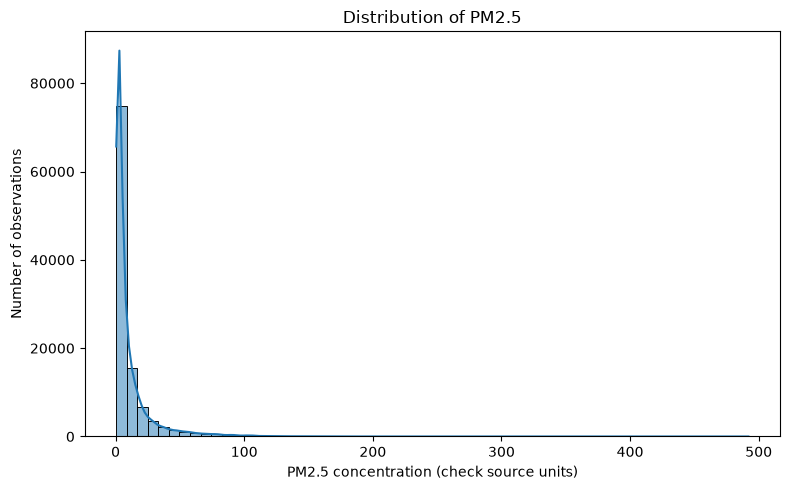

In [27]:
plt.figure(figsize=(8, 5))
values = data["pm2_5"].dropna()
sns.histplot(data=data, x="pm2_5", bins=60,kde=True)
plt.title("Distribution of PM2.5")
plt.xlabel("PM2.5 concentration (check source units)")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()


### Graph 2: compare PM2.5 distributions across selected cities with the most records.

In [40]:
top_cities = data["city_name"].value_counts().head(12).index
city_sample = data[data["city_name"].isin(top_cities) & data["pm2_5"].notna()]
city_names = list(top_cities)
box_values = [city_sample.loc[city_sample["city_name"] == city, "pm2_5"].values for city in city_names]
plt.figure(figsize=(11, 6))
plt.boxplot(box_values, labels=city_names, showfliers=False)
plt.xticks(rotation=45, ha="right")
plt.title("PM2.5 by city (cities with most records)")
plt.xlabel("City")
plt.ylabel("PM2.5 concentration (check source units)")
plt.tight_layout()
plt.show()


TypeError: boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

<Figure size 1100x600 with 0 Axes>

### Graph 3: PM2.5 against wind speed; a trend is not proof of causation.

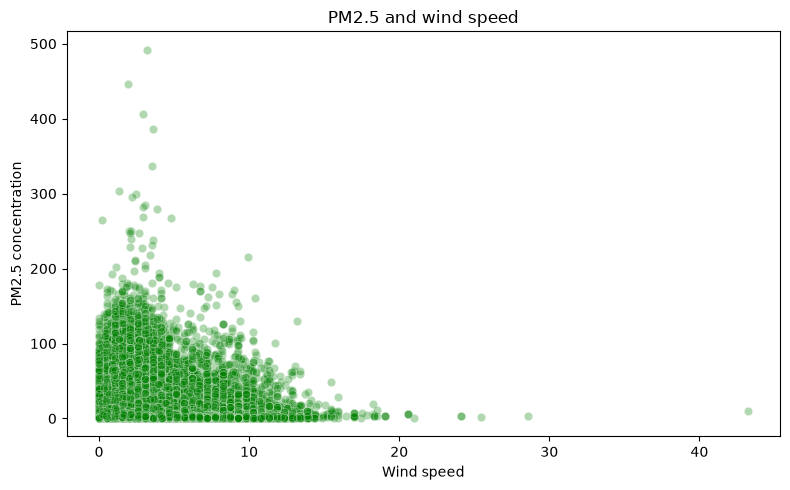

In [34]:

plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x="wind_speed", y="pm2_5", alpha=0.3,color="green")
plt.title("PM2.5 and wind speed")
plt.xlabel("Wind speed")
plt.ylabel("PM2.5 concentration")
plt.tight_layout()
plt.show()


### Graph 4: correlation heatmap for numeric pollution and weather fields.

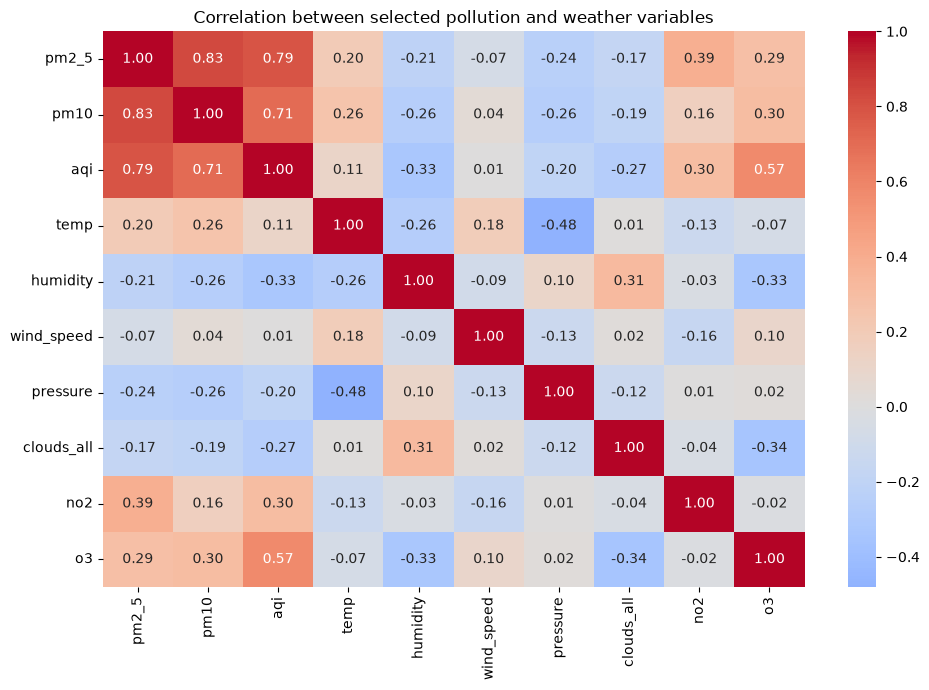

In [35]:
heat_cols = [c for c in ["pm2_5", "pm10", "aqi", "temp", "humidity",
                         "wind_speed", "pressure", "clouds_all", "no2", "o3"]
            if c in data.columns]
plt.figure(figsize=(10, 7))
sns.heatmap(data[heat_cols].corr(numeric_only=True), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlation between selected pollution and weather variables")
plt.tight_layout()
plt.show()


### Graph 5: compare PM2.5 across weather conditions

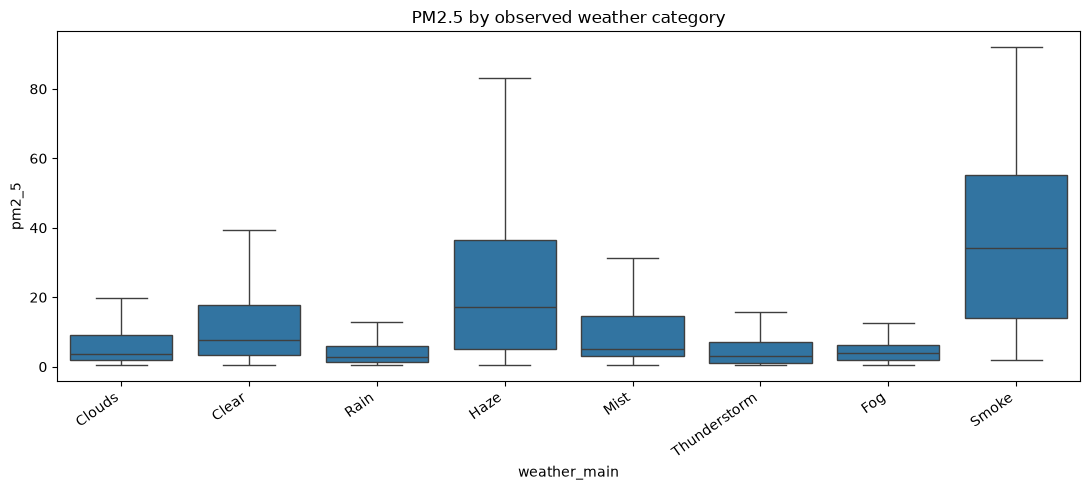

In [36]:

if "weather_main" in data.columns:
    order = data.groupby("weather_main")["pm2_5"].count().sort_values(ascending=False).head(8).index
    plt.figure(figsize=(11, 5))
    sns.boxplot(data=data[data["weather_main"].isin(order)], x="weather_main",
                y="pm2_5", order=order, showfliers=False)
    plt.xticks(rotation=35, ha="right")
    plt.title("PM2.5 by observed weather category")
    plt.tight_layout()
    plt.show()


,continent
pm2_5,
4.71,NaN
4.71,NaN
28.41,NaN
18.07,NaN
31.45,NaN
...,...
5.36,NaN
5.64,NaN
1.50,NaN


### Graph 6: missing values by column


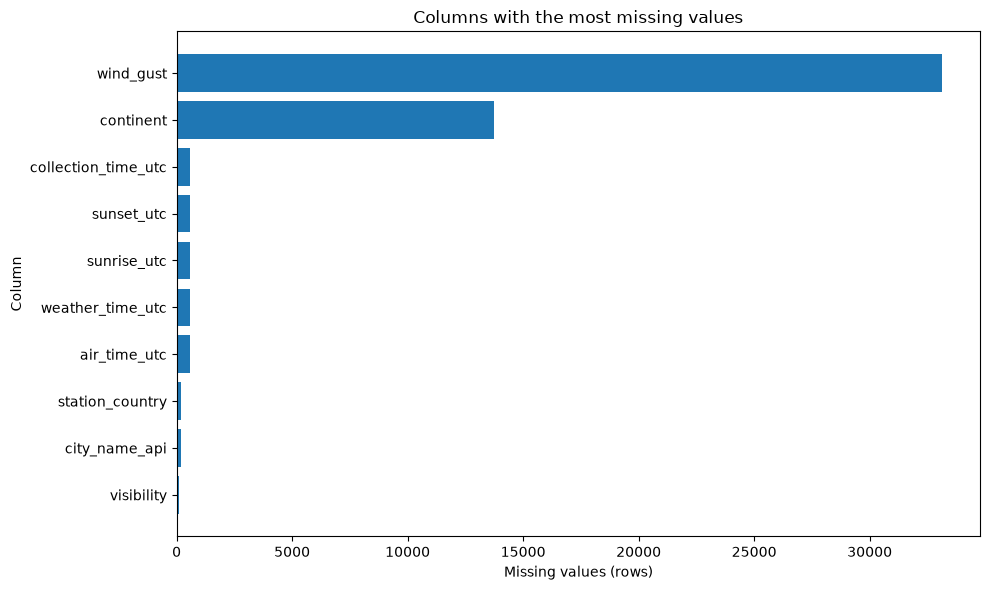

In [37]:
missing_counts = data.isna().sum().sort_values(ascending=False)
missing_counts = missing_counts[missing_counts > 0].head(20)
plt.figure(figsize=(10, 6))
if len(missing_counts):
    plt.barh(missing_counts.index[::-1], missing_counts.values[::-1])
    plt.xlabel("Missing values (rows)")
    plt.ylabel("Column")
    plt.title("Columns with the most missing values")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the cleaned data.")


### Graph 7 : Box PLot by Region 

- PM2.5 Dsitribution Among Continent 

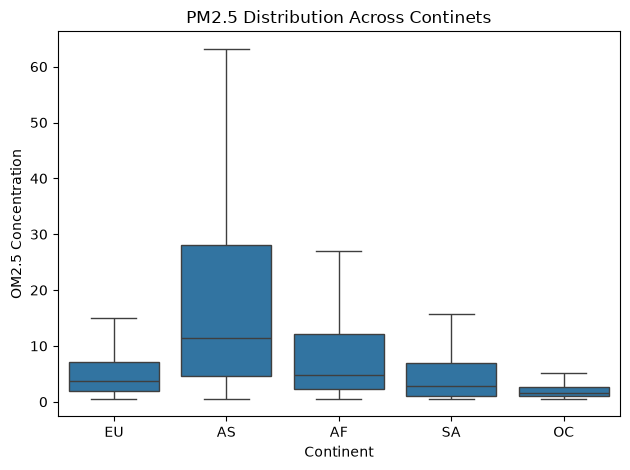

In [42]:
sns.boxplot(data=data,x="continent",y="pm2_5",showfliers=False)
plt.title("PM2.5 Distribution Across Continets")
plt.xlabel("Continent")
plt.ylabel("OM2.5 Concentration")
plt.tight_layout()
plt.show()


## 7. Five hypothesis tests
Use **α = 0.05**. For every test, H₀ is the null hypothesis. If p < 0.05, reject H₀; otherwise, fail to reject H₀. Statistical significance does not prove causation. These tests are illustrative and should only be reported when group sizes and data quality are adequate. Because measurements may be clustered by country/city and the data is a snapshot, results are exploratory.

In [45]:
# Libraries for the five requested tests
from scipy import stats
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest

alpha = 0.05
test_data = data.copy()
# AQI is treated as a categorical index; high AQI here means category 3–5.
test_data["high_aqi"] = np.where(test_data["aqi"].notna(), (test_data["aqi"] >= 3).astype(int), np.nan)
# Missing rainfall is not automatically considered dry.
test_data["rain_status"] = np.where(test_data["rain_1h"].isna(), np.nan, (test_data["rain_1h"] > 0).astype(int))
print("Significance level alpha =", alpha)



Significance level alpha = 0.05


#### TEST 1: One-sample proportion z-test

- Is the proportion of high-AQI observations different from a 20% benchmark?
  
>H₀: The high-AQI proportion equals 20%.

>H₁: The high-AQI proportion differs from 20%.

In [46]:
valid_aqi = test_data["high_aqi"].dropna().astype(int)
high_aqicount = int(valid_aqi.sum())
totalcount = len(valid_aqi)
if totalcount:
    z_stat, p_value = proportions_ztest(count=high_aqicount, nobs=totalcount, value=0.20)
    print(f"One-sample proportion z-test: z={z_stat:.3f}, p={p_value:.5g}, n={totalcount}")
    print(f"Observed high-AQI proportion: {high_aqicount / totalcount:.3%}")
    print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")
else:
    print("Test skipped: no valid AQI observations.")


One-sample proportion z-test: z=-23.107, p=3.9178e-118, n=108467
Observed high-AQI proportion: 17.344%
Decision: Reject H0


#### Test 2: Two Sample t-test

Is mean PM2.5 different between rainy and non-rainy observations?
>- H₀: The mean PM2.5 values are equal.
>- H₁: The mean PM2.5 values are different.

In [47]:
rainy_pm25 = test_data.loc[test_data["rain_status"] == 1, "pm2_5"].dropna()
dry_pm25 = test_data.loc[test_data["rain_status"] == 0, "pm2_5"].dropna()
if len(rainy_pm25) >= 2 and len(dry_pm25) >= 2:
    t_stat, p_value = stats.ttest_ind(rainy_pm25, dry_pm25, equal_var=False, nan_policy="omit")
    print(f"Welch two-sample t-test: t={t_stat:.3f}, p={p_value:.5g}")
    print("Rainy n/mean:", len(rainy_pm25), rainy_pm25.mean())
    print("Non-rainy n/mean:", len(dry_pm25), dry_pm25.mean())
    print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")
else:
    print("Test skipped: need at least two valid PM2.5 values in each group.")


Welch two-sample t-test: t=-43.363, p=0
Rainy n/mean: 13968 6.381211340206185
Non-rainy n/mean: 94499 11.258909935554874
Decision: Reject H0


#### Test 3 — Chi-square test of independence

In [48]:
common_weather = df["weather_main"].value_counts().head(6).index

weather_data= df[["weather_main","aqi"]].copy()
weather_data["weather_group"]=np.where(weather_data["weather_main"].isin(common_weather),
                                        weather_data["weather_main"],"Others"
                                       )



In [49]:
common_weather

Index(['Clouds', 'Clear', 'Rain', 'Haze', 'Mist', 'Thunderstorm'], dtype='str', name='weather_main')

In [50]:
contingency_table = pd.crosstab(weather_data["weather_group"], weather_data["aqi"]).dropna(axis=0, how="all")
if contingency_table.shape[0] >= 2 and contingency_table.shape[1] >= 2:
    chi_stats, p_value, degree_freedom, expected = chi2_contingency(contingency_table)
    print("Chi-square test of independence")
    print(f"chi2={chi_stats:.3f}, df={degree_freedom}, p={p_value:.5g}")
    print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")
    display(contingency_table)
else:
    print("Test skipped: contingency table needs at least two categories on each axis.")


Chi-square test of independence
chi2=11126.230, df=24, p=0
Decision: Reject H0


aqi,1,2,3,4,5
weather_group,,,,,
Clear,8492,12971,5248,2291,1854
Clouds,33381,21292,5496,1588,1119
Haze,108,61,101,29,21
Mist,94,55,25,11,6
Others,65,85,43,19,25
Rain,9901,2994,683,161,77
Thunderstorm,119,37,8,7,0


#### Test 4 — One-way ANOVA

Does mean PM2.5 differ across continents?
>- H₀: All included continents have the same mean PM2.5.
>- H₁: At least one continent has a different mean.

In [51]:
continentwise_data = test_data[["continent", "pm2_5"]].dropna()
counts = continentwise_data["continent"].value_counts()
valid_continent = counts[counts >= 10].index
groups = [continentwise_data.loc[continentwise_data["continent"] == continent, "pm2_5"].values for continent in valid_continent]
if len(groups) >= 2:
    f_stat, p_value = stats.f_oneway(*groups)
    print(f"One-way ANOVA: F={f_stat:.3f}, p={p_value:.5g}")
    print("Continents included:", list(valid_continent))
    print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")
else:
    print("Test skipped: fewer than two continents have at least 10 valid PM2.5 readings.")


One-way ANOVA: F=3626.113, p=0
Continents included: ['AF', 'AS', 'EU', 'SA', 'OC']
Decision: Reject H0


#### TWO PROPORTION Z TEST 

Does the proportion of High-AQi observations differ between rainy and non rainy condition?

>- H₀: The two proportions are equal.
>- H₁: The two proportions are different.


In [52]:
valid = test_data.dropna(subset=["rain_status", "high_aqi"])
rainy = valid[valid["rain_status"] == 1]
dry = valid[valid["rain_status"] == 0]
counts = [int(rainy["high_aqi"].sum()), int(dry["high_aqi"].sum())]
sizes = [len(rainy), len(dry)]
if min(sizes) > 0:
    z_stat, p_value = proportions_ztest(count=counts, nobs=sizes)
    print(f"Two-proportion z-test: z={z_stat:.3f}, p={p_value:.5g}")
    print("Rainy high-AQI proportion:", rainy["high_aqi"].mean(), "(n=", sizes[0], ")")
    print("Non-rainy high-AQI proportion:", dry["high_aqi"].mean(), "(n=", sizes[1], ")")
    print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")
else:
    print("Test skipped: both rain groups need observations.")


Two-proportion z-test: z=-35.543, p=1.0664e-276
Rainy high-AQI proportion: 0.06715349369988545 (n= 13968 )
Non-rainy high-AQI proportion: 0.18914485867575317 (n= 94499 )
Decision: Reject H0


## 8. results into defensible insights
PM2.5 and wind speed were associated in this sample


## 9. Export for Power BI
Creating a clean table with one row per city/measurement timestamp. Keep numeric values numeric and timestamps as datetime. Export only useful columns:

In [53]:
powerbi_cols = [c for c in [
    "collection_time_utc", "country_name", "continent", "city_name",
    "geo_lat", "geo_lon", "aqi", "pm2_5", "pm10", "no2", "o3",
    "temp", "humidity", "wind_speed", "pressure", "rain_1h",
    "weather_main", "season"
] if c in data.columns]

powerbi_data = data[powerbi_cols].copy()
powerbi_data.to_csv("air_pollution_weather_clean.csv", index=False)
print("Saved Power BI file: air_pollution_weather_clean.csv")

Saved Power BI file: air_pollution_weather_clean.csv


### Beginner Power BI dashboard plan
1. **KPI cards:** average PM2.5, average PM10, average AQI, number of cities.
2. **Map:** city latitude/longitude, colour or size by PM2.5.
3. **Bar chart:** median PM2.5 by country or city.
4. **Scatter plot:** PM2.5 vs wind speed, with temperature as colour if desired.
5. **Slicers:** country, continent, city, weather category.


### Presentation
Problem → dataset and limitations → cleaning → EDA charts → hypothesis tests → 3 evidence-backed findings → recommendations and next steps.